# 과제1 조업형태 분류 추론과 평가

제공된 Test A 관측을337개 특징으로 요약하고, 선택된63회차 가중치로 예측한다. 최종 판정은compact/state의14과제를 사용한다. 이 노트북은 코드의 실제 추론 함수를 호출한다.


In [1]:
from pathlib import Path
import os, sys, json, subprocess
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'model' / 'round63.ckpt').exists())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'src' / 'vendor')]
import numpy as np
import pandas as pd
print('Round63 | 과제1 | 고정 모델 실행')

Round63 | 과제1 | 고정 모델 실행


## 입력 데이터

원자료의 필수 열은 `part_dt`, `rfid_id`, `rfid_time`, `geom`이다. 포함된 특징은공식 대상100척만 처리한 값이다. 라벨을 읽지 않으며,ID는결과연결에만 사용한다. 원자료부터 계산하려면아래 `INPUT_DIR`에월별CSV폴더를 지정한다.


In [2]:
INPUT_DIR = None  # 예: Path('D:/대회자료/테스트셋')
if INPUT_DIR is not None:
    subprocess.run([sys.executable, str(ROOT/'scripts/build_features.py'), '--input', str(INPUT_DIR)], check=True)
features = pd.read_csv(ROOT/'data/testA/features.csv', index_col='id')
audit = json.loads((ROOT/'data/testA/features.audit.json').read_text(encoding='utf-8'))
assert features.shape == (100, 337)
print({'대상선박': len(features), '특징': features.shape[1], '추출관측행': audit['target_rows'], '라벨열사용': audit['label_columns_read']})
features[['n_rows','n_days','length_sum_km']].head()

{'대상선박': 100, '특징': 337, '추출관측행': 22733, '라벨열사용': False}


,n_rows,n_days,length_sum_km
id,,,
36111894,1,1,0.000000
36112256,64,15,47.069019
36001376,1,1,0.000000
31011023,2,1,0.002580
31004911,74,10,551.959530


## 고정 모델과 판정 설정

본체는ICL중간4블록과뒤4블록FFN게이트를학습한63회차모델이다. 문맥은기존FIT4,423척으로고정했다. 관계분기비중0,본체비중1이다. 최종로그점수를softmax로정규화해선택클래스의확률을저장한다.


In [3]:
policy = json.loads((ROOT/'model/policy.json').read_text(encoding='utf-8'))
provenance = json.loads((ROOT/'model/provenance.json').read_text(encoding='utf-8'))
print({'epoch': provenance['selected_epoch'], 'update': provenance['selected_updates'], 'FIT문맥': provenance['fixed_context_boats'], '정책': policy})

{'epoch': 1, 'update': 2, 'FIT문맥': 4423, '정책': {'alpha': 0.5, 'weights': [1.0, 1.0, 1.0, 0.8], 'state_beta': 0.5, 'relation_beta': 0.0, 'body_gamma': 1.0, 'query_batch_size': 1000, 'probability': 'softmax(final_log_score),chosen_class', 'normalization_order': ['none', 'power']}}


## Test A 실제 추론

CLI와같은 `predict_to_csv`를사용한다. 각과제의전처리는문맥에만적합하고,한번읽은본체를공유한다.


In [4]:
from round63.pipeline import predict_to_csv
result = predict_to_csv(ROOT, ROOT/'data/testA/features.csv', ROOT/'outputs/testA_predictions.csv')
assert len(result) == 100 and result.iloc[:,2].between(0,1).all()
print(result.iloc[:,1].value_counts().to_dict())
result.head(10)

{"task": "compact_head", "seed": 20262015, "context_boats": 4423, "query_boats": 100, "features": 150, "seconds": 6.869601999991573}


{"task": "compact_pair_0_1", "seed": 20262206, "context_boats": 3702, "query_boats": 100, "features": 150, "seconds": 4.679469300084747}


{"task": "compact_pair_0_2", "seed": 20262207, "context_boats": 2816, "query_boats": 100, "features": 150, "seconds": 4.095890299999155}


{"task": "compact_pair_0_3", "seed": 20262208, "context_boats": 2285, "query_boats": 100, "features": 150, "seconds": 3.621603099978529}


{"task": "compact_pair_1_2", "seed": 20262217, "context_boats": 2138, "query_boats": 100, "features": 150, "seconds": 3.5450203999644145}


{"task": "compact_pair_1_3", "seed": 20262218, "context_boats": 1607, "query_boats": 100, "features": 150, "seconds": 3.059118099976331}


... (6 outputs left out)

{"task": "state_pair_1_3", "seed": 20262218, "context_boats": 1607, "query_boats": 100, "features": 337, "seconds": 5.617764199967496}


{"task": "state_pair_2_3", "seed": 20262228, "context_boats": 721, "query_boats": 100, "features": 337, "seconds": 4.446794099989347}


{'연안복합': 80, '자망': 15, '통발': 3, '채낚기연승낚시': 2}


,rfid_id,예측 조업형태,예측조업형태 확률
0,36111894,연안복합,0.463364
1,36112256,연안복합,0.685952
2,36001376,연안복합,0.653439
3,31011023,연안복합,0.475324
4,31004911,연안복합,0.554181
5,36306212,연안복합,0.503995
6,36004634,연안복합,0.508431
7,36102984,연안복합,0.418370
8,32400280,연안복합,0.425657
9,36303527,연안복합,0.669632


## 내부 REPORT 회귀 확인

기존검증구간을새추론코드로예측해63회차기록과비교했다. 아래는그실행기록이다. `RUN_REGRESSION=True`로바꾸면2,949척을다시추론한다.


In [5]:
RUN_REGRESSION = False
if RUN_REGRESSION:
    subprocess.run([sys.executable, str(ROOT/'scripts/validate_report.py')], check=True)
regression = json.loads((ROOT/'validation/report_regression.json').read_text(encoding='utf-8'))
assert regression['passed'] and regression['changed_predictions'] == 0
print(regression)

{'passed': True, 'all_query_boats': 2949, 'changed_predictions': 0, 'REPORT_micro_f1': 0.6122033898305085, 'TUNE_micro_f1': 0.601763907734057, 'normalized_probability_sums': True, 'deployed_tasks': 14, 'training_performed': False, 'maximum_log_score_difference': 6.887263275245914e-07}


## 결과 그림


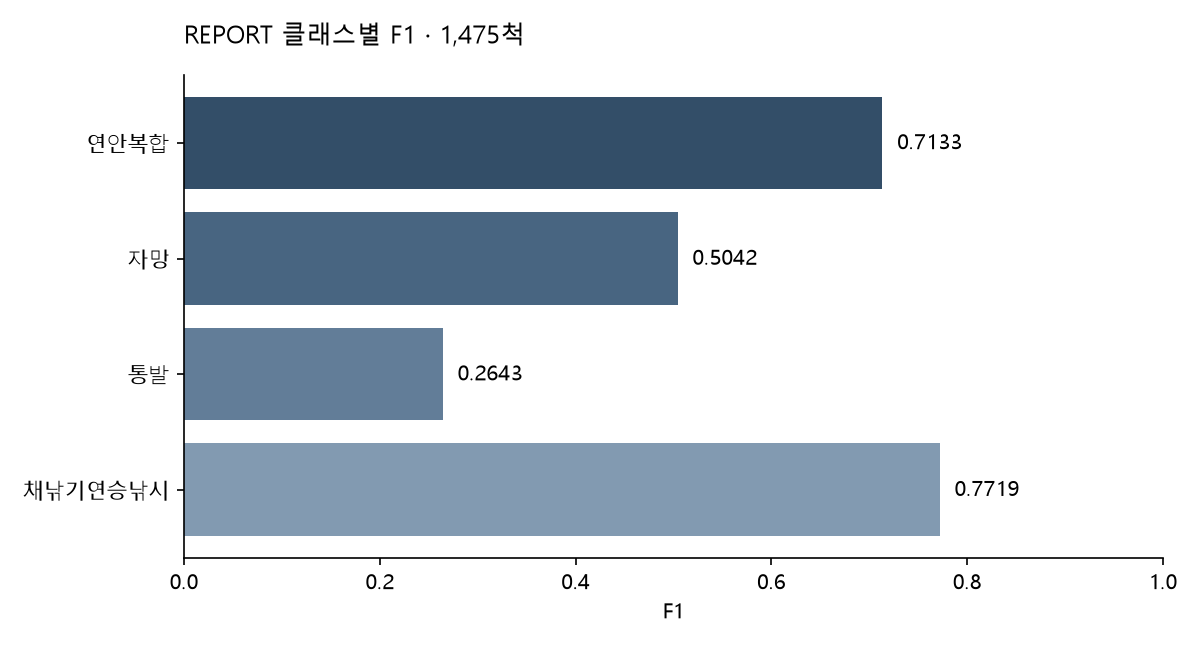

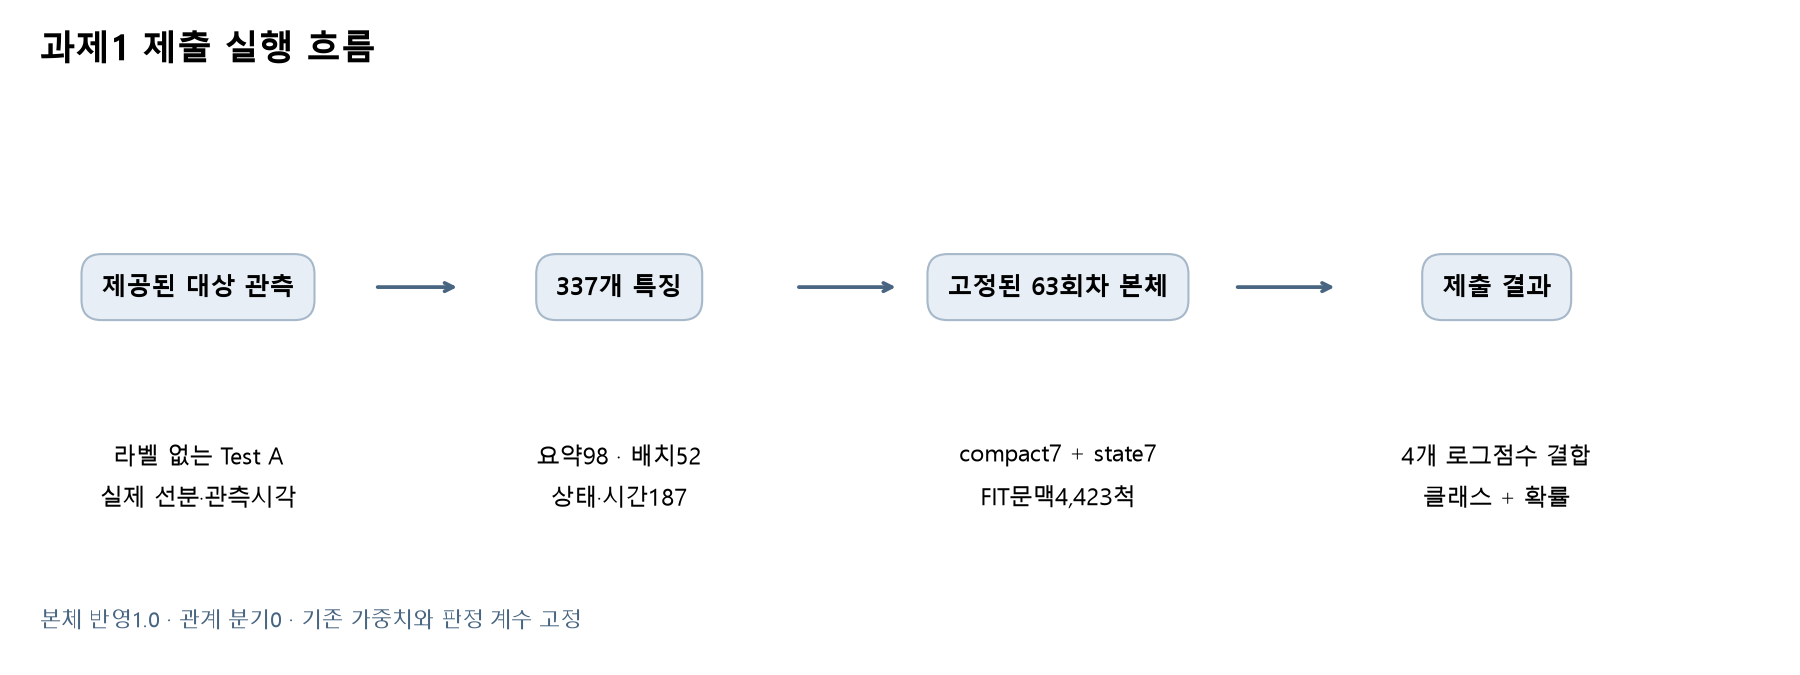

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/report_class_f1.png')))
display(Image(filename=str(ROOT/'figures/model_flow.png')))

## 제출 결과

과제1과 과제2의 공식 대상100척을 최종 엑셀에 통합했습니다.


In [7]:
from openpyxl import load_workbook
path = ROOT/'outputs/제출결과_최종.xlsx'
book = load_workbook(path, read_only=True, data_only=True)
rowsA = list(book.worksheets[0].values)
rowsB = list(book.worksheets[1].values)
print({'시트': book.sheetnames, 'TestA행': len(rowsA)-1, 'TestB행': len(rowsB)-1, 'TestB완료': all(row[1] is not None for row in rowsB[1:])})
book.close()